# 10 · 错误审查：剩下的错误是什么

**目的。**notebook 09 选中的方案 C 在测试集上还剩约 1.8%（触控笔）和 1.2%（手指）的错误。在继续改模型（notebook 11、12）之前，先弄清楚这些错误**能不能改、值不值得改**。每个错误分到三类之一：

| 类别 | 含义 | 对后续的意义 |
|---|---|---|
| **模型读错** | 人一看就知道是什么数字，模型错了 | 可以靠更好的数据、模型、个性化来修 |
| **人眼也难分** | 单看这一个样本，人也说不准（比如带长勾的 1 和 7，潦草得看不出） | 基本修不了；游戏里只能靠"屏幕上的答案"来兜底 |
| **疑似标签错误** | 写的明显是另一个数字（被要求写 2，写成了 3） | 不算模型的错；修正标签后准确率会变 |

"模型读错"里再分两种：**常见写法**（这个人别的同类数字模型都认对了，这一个恰好不行）和**此人的固定写法**（这个人的这个数字几乎都被认错，属于训练数据里没有的个人风格，notebook 14 的个性化正好针对它）。

**方法：我先自动初筛，你来确认。**

1. 初筛完全基于可以复核的规则（第 3 节）：8 个模型（notebook 09 的 4 个方案 × 2 个种子）投票是否一致、方案 C 的置信度，以及**这个样本和同一个人写的其他样本更像哪个数字**。最后一条是关键：同一个人的写法很稳定，如果一个标成 2 的样本，看起来和这个人自己写的 3 几乎一样，而和他写的 2 不像，那多半是写错了数字。
2. 第 4 节按类别列出所有错误，方便浏览。
3. 第 8 节生成一个本地网页，每个错误一张卡片：放大的笔迹、模型看到的 28×28 图、同一个人写的其他样本，可以一键改类别并导出。你确认后，第 9 节读入你的结果，重新计算所有数字。

**范围。**只审查**测试集**（Pendigits test 14 人，触控笔；Corr test 177 人，手指）。验证集和训练集不看，避免"看了测试集再调模型"。

In [1]:
import json, pickle, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import keras

sys.path.insert(0, '.')
import evaluate

REAL = Path('cache/real'); RESULTS = Path('results'); MODEL_DIR = Path('cache/models'); AUDIT = Path('cache/audit')
AUDIT.mkdir(parents=True, exist_ok=True)
CONFIGS, SEEDS = 'ABCD', [42, 43]
plt.rcParams['figure.dpi'] = 110

## 1. 数据和模型输出

8 个模型对全部真实样本的输出算一次，存在 `cache/real/probs09.npz`。方案 C 的预测取两个种子的平均概率（和 notebook 09 第 6 节一样）。

In [2]:
d = np.load(REAL / 'real_digits.npz')
meta = pd.DataFrame({k: d[k] for k in ['source', 'device', 'writer', 'split']}); meta['label'] = d['y']
x = d['x'].astype(np.float32) / 255
y = d['y']
with open(REAL / 'real_strokes.pkl', 'rb') as f:
    strokes = [s['strokes'] for s in pickle.load(f)]

PROBS = REAL / 'probs09.npz'
if not PROBS.exists():
    out = {}
    for c in CONFIGS:
        for s in SEEDS:
            m = keras.models.load_model(MODEL_DIR / f'real09_{c}_s{s}.keras')
            out[f'{c}_{s}'] = m.predict(x[..., None], batch_size=2048, verbose=0)
    np.savez_compressed(PROBS, **out)
P = dict(np.load(PROBS))
pC = (P['C_42'] + P['C_43']) / 2; predC = pC.argmax(1)
pA = (P['A_42'] + P['A_43']) / 2; predA = pA.argmax(1)
votes = np.stack([P[k].argmax(1) for k in P], 1)            # (n, 8): every model's answer

TESTS = {'pen': (meta.source == 'pendigits') & (meta.split == 'test'),
         'finger': (meta.source == 'corr') & (meta.split == 'test')}
for name, k in TESTS.items():
    n, e = int(k.sum()), int((k & (predC != y)).sum())
    print(f'{name:6s} test: {n:5d} samples, {e:3d} errors, accuracy {1 - e / n:.2%}, writers {meta.writer[k].nunique()}')

pen    test:  3498 samples,  61 errors, accuracy 98.26%, writers 14
finger test: 14017 samples, 168 errors, accuracy 98.80%, writers 177


## 2. 错误的整体分布

### 2.1 错误集中在少数人身上吗

如果错误平均分布在所有人身上，说明是模型的普遍问题；如果集中在少数人身上，说明是**个人写法**的问题。下图把每个人的错误数从多到少排开。

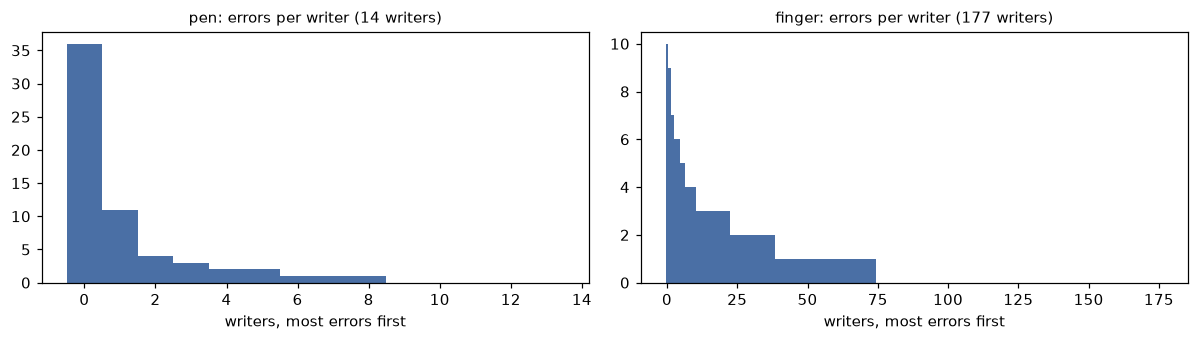

,pen,finger
writers,14,177
errors,61,168
top writer,pd-b13,co224
top writer errors,36,10
top 5% of writers,1,9
their share of errors,0.59,0.333
writers with no error,5,102


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
conc = {}
for ax, (name, k) in zip(axes, TESTS.items()):
    err = k & (predC != y)
    per = meta.writer[err].value_counts().reindex(meta.writer[k].unique(), fill_value=0).sort_values(ascending=False)
    ax.bar(range(len(per)), per.values, color='#4a6fa5', width=1.0)
    ax.set_title(f'{name}: errors per writer ({len(per)} writers)', fontsize=10); ax.set_xlabel('writers, most errors first')
    top = max(1, round(0.05 * len(per)))
    conc[name] = {'writers': len(per), 'errors': int(per.sum()), 'top writer': per.index[0], 'top writer errors': int(per.iloc[0]),
                  'top 5% of writers': top, 'their share of errors': round(per.iloc[:top].sum() / per.sum(), 3),
                  'writers with no error': int((per == 0).sum())}
plt.tight_layout(); plt.show()
pd.DataFrame(conc)

### 2.2 最常见的混淆

In [4]:
pairs = {}
for name, k in TESTS.items():
    e = np.flatnonzero(k & (predC != y))
    s = pd.Series([f'{a} → {b}' for a, b in zip(y[e], predC[e])]).value_counts()
    pairs[name] = s.head(10)
    print(f'{name}:', ', '.join(f'{p} ×{n}' for p, n in s.head(10).items()))

pen: 4 → 5 ×12, 7 → 2 ×11, 4 → 6 ×11, 9 → 7 ×4, 1 → 7 ×3, 9 → 3 ×3, 6 → 1 ×3, 3 → 7 ×2, 4 → 9 ×2, 1 → 2 ×2
finger: 8 → 6 ×34, 3 → 7 ×18, 4 → 6 ×15, 1 → 7 ×12, 1 → 2 ×11, 7 → 2 ×7, 5 → 3 ×5, 8 → 0 ×5, 5 → 6 ×5, 7 → 4 ×5


## 3. 自动初筛

### 3.1 每个错误算三组证据

1. **模型投票**：8 个模型里有几个给出和方案 C 相同的错误答案（8/8 表示所有模型都这么认为，1–5/8 表示模型之间意见不一）。
2. **置信度**：方案 C 给错误答案的概率 `p_pred`、给正确标签的概率 `p_label`。
3. **和本人其他样本的相似度**：把这个样本和**同一个人写的其他所有样本**比（28×28 图稍作模糊后的余弦相似度，和模型无关），取最像的 5 个，数一数其中几个是"标签数字"（`own_label`）、几个是"模型给的数字"（`own_pred`）。手指数据每人每个数字写了 8 遍，触控笔数据约 25 遍，足够做这个比较。

### 3.2 规则（按顺序，先满足的先归类）

| 顺序 | 类别 | 条件 | 理由 |
|---|---|---|---|
| 1 | 疑似标签错误 | `own_pred ≥ 3` 且 `own_label ≤ 2` 且投票 ≥ 7/8 且 `p_pred ≥ 0.6` | 看起来像本人写的另一个数字，而且所有模型都很确定 |
| 2 | 人眼也难分 | 投票 ≤ 5/8，或 `own_label ≤ 2` | 模型之间意见不一；或者连本人写的同一个数字都不像 |
| 3 | 模型读错 | 其余（像本人写的同一个数字，模型却一致认错） | |

"模型读错"再分：这个人的这个数字在测试集里**一半以上都被认错** → **此人的固定写法**；否则 → **常见写法**。

这些规则只是初筛，阈值是我根据经验定的，不追求精确，目的是把需要人看的样本排好序。最终以你的确认为准。

In [5]:
feat = gaussian_filter(x, (0, 1, 1)).reshape(len(x), -1)
feat /= np.linalg.norm(feat, axis=1, keepdims=True) + 1e-9
by_writer = meta.groupby('writer').indices

rows = []
for name, k in TESTS.items():
    for i in np.flatnonzero(k & (predC != y)):
        w = by_writer[meta.writer[i]]; w = w[w != i]
        nn = w[np.argsort(-(feat[w] @ feat[i]))[:5]]
        same = w[(y[w] == y[i]) & TESTS[name].to_numpy()[w]]
        rows.append({'id': int(i), 'set': name, 'writer': meta.writer[i], 'label': int(y[i]), 'pred': int(predC[i]),
                     'p_pred': float(pC[i, predC[i]]), 'p_label': float(pC[i, y[i]]),
                     'votes': int((votes[i] == predC[i]).sum()),
                     'own_label': int((y[nn] == y[i]).sum()), 'own_pred': int((y[nn] == predC[i]).sum()),
                     'writer_digit_acc': float((predC[same] == y[same]).mean()) if len(same) else np.nan,
                     'A_right': bool(predA[i] == y[i])})
audit = pd.DataFrame(rows).set_index('id')

def screen(r):
    if r.own_pred >= 3 and r.own_label <= 2 and r.votes >= 7 and r.p_pred >= 0.6:
        return 'label', 'looks like this writer\'s own %d; all models agree' % r.pred
    if r.votes <= 5:
        return 'ambiguous', f'models split ({r.votes}/8)'
    if r.own_label <= 2:
        return 'ambiguous', f'unlike this writer\'s other {r.label}s'
    if r.writer_digit_acc < 0.5:
        return 'model', f'this writer\'s own style: {r.writer_digit_acc:.0%} of their {r.label}s read right'
    return 'model', f'like this writer\'s other {r.label}s, which are read right ({r.writer_digit_acc:.0%})'

audit[['rule', 'reason']] = audit.apply(lambda r: pd.Series(screen(r)), axis=1)
print(pd.crosstab(audit.rule, audit.set, margins=True))

set        finger  pen  All
rule                       
ambiguous      66   15   81
label          17    0   17
model          85   46  131
All           168   61  229


### 3.3 我的目视修正

规则只看数字，会犯一些明显的错。我把规则的结果全部看了一遍（第 4 节的图），对**一眼就能判断**的按写法成批修正，每一批都写明理由。拿不准的不改，留给你确认。修正后的类别是 `screen`，第 7 节的上限和第 8 节的审查网页都用它；规则原本的结果保留在 `rule` 列。

In [6]:
VISUAL = [   # (category, reason, sample ids)
    ('model', 'writer pd-b13 writes every 4 the same one-stroke way (no upper half of the vertical): their own style',
     [int(i) for i in audit.index[(audit.writer == 'pd-b13') & (audit.label == 4)]]),
    ('model', 'flat-top 3 (written like a Z with a curl): people read it as 3',
     [17057, 19898, 23524, 11887, 11894, 19831, 19847, 21651, 21767, 22116, 30738, 19269]),
    ('model', '1 with a foot and/or a short flag: people read it as 1',
     [24900, 26317, 30685, 12346, 8439, 10760]),
    ('model', '4 written as an L plus a short vertical: people read it as 4', [12462, 12531, 16009, 16060, 12647, 14432]),
    ('model', '8 in one stroke whose two loops still cross clearly', [17053, 22778, 24445, 17103, 15080, 22793, 23263, 23566]),
    ('model', 'crossed 7 (European style)', [11077, 22093, 22498]),
    ('model', '2 with a small loop at the turn', [27659, 27703]),
    ('model', 'slashed 0', [23512]),
    ('model', '5 with its top bar written apart', [13244]),
    ('model', '6 with a small loop', [14258]),
    ('ambiguous', '1 with a long flag: could as well be a 7', [19522, 19528, 30480, 30493, 13602]),
    ('ambiguous', '9 with an open loop: reads as 7 or ?', [9102, 10379, 10845, 8582, 12397, 14119]),
    ('ambiguous', 'open-top 8 that looks like a 6 or an L', [24664, 26635, 29619, 22509]),
    ('ambiguous', '5 without its top bar: reads as 3', [29713, 29723]),
    ('ambiguous', 'shape between two digits', [26623, 26611, 26630, 12555, 18530, 27674, 10796, 8561, 8246, 8998, 21384, 19340]),
]
audit['screen'], audit['why'] = audit.rule, audit.reason
for cat, why, ids in VISUAL:
    ids = [i for i in ids if i in audit.index]
    audit.loc[ids, 'screen'] = cat; audit.loc[ids, 'why'] = 'visual: ' + why
audit['style'] = np.where(audit.screen != 'model', '', np.where(audit.writer_digit_acc < 0.5, 'writer style', 'common'))
print('changed by the visual pass:', int((audit.screen != audit.rule).sum()), 'of', len(audit))
print(pd.crosstab(audit.rule, audit.screen, margins=True).rename_axis(index='rule', columns='after visual pass'))
print(); print(pd.crosstab([audit.screen, audit['style']], audit.set))

changed by the visual pass: 76 of 229
after visual pass  ambiguous  label  model  All
rule                                           
ambiguous                 41      0     40   81
label                      3      7      7   17
model                     26      0    105  131
All                       70      7    152  229

set                     finger  pen
screen    style                    
ambiguous                   56   14
label                        7    0
model     common            99   23
          writer style       6   24


## 4. 按类别浏览（目视修正之后）

每个小图是**原始笔迹**（不是 28×28 图），标题是"样本编号 · 标签→模型答案 · p_pred"。圆点是每一笔的起点。不同颜色是不同的笔画；手指数据（Corr）笔画之间的先后顺序在 notebook 07 的解析里没有还原，颜色**不代表**先后。

> **更正 notebook 07。**07 说 Corr 的笔画先后"无法还原"，这是错的。`stroke` 表里的 `Z_FOK_GLYPH` 是 Core Data 为"有序关系"记录的顺序键，就是笔画的真实先后：两笔写成的 7，按它排序后 99.9% 是"短的横线在第二笔"，4 是 99.0%，5 是 87.3%；而按 07 用的 `ZINDEX` 排序都只有约 52%，等于随机。画成 28×28 的图和笔画先后无关，所以 07–10 的所有结果不受影响；notebook 11 的轨迹模型会改用 `Z_FOK_GLYPH`。

suspected label error · pen (0) : none


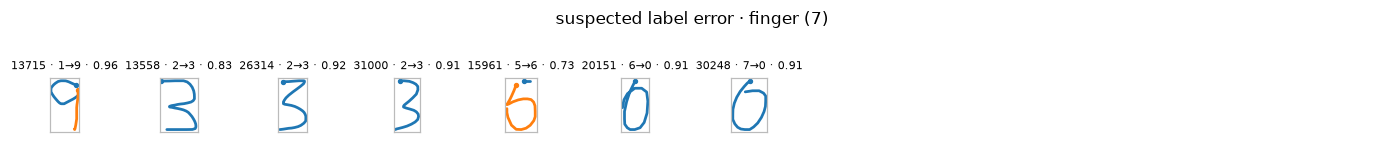

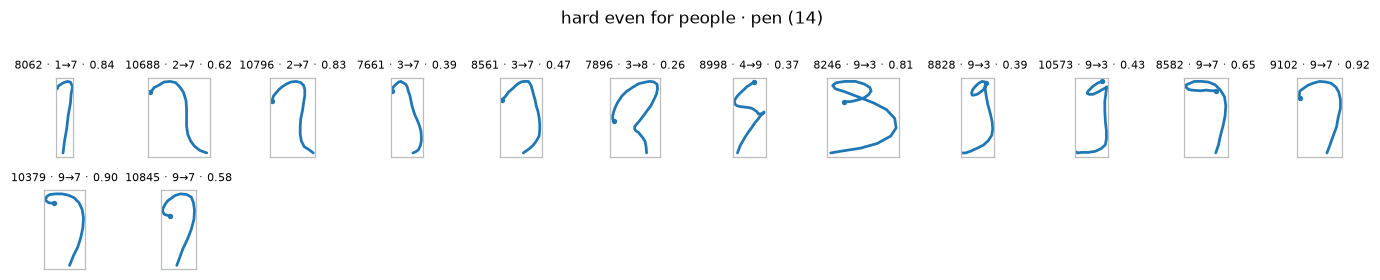

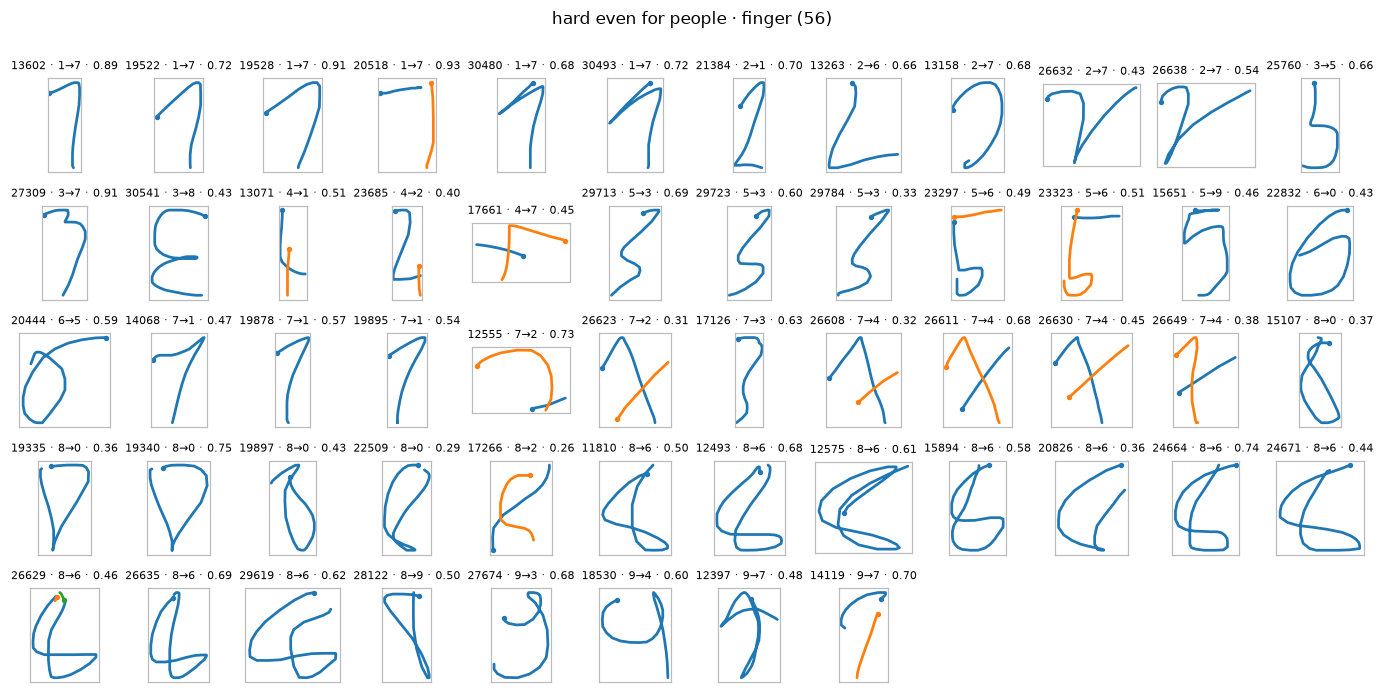

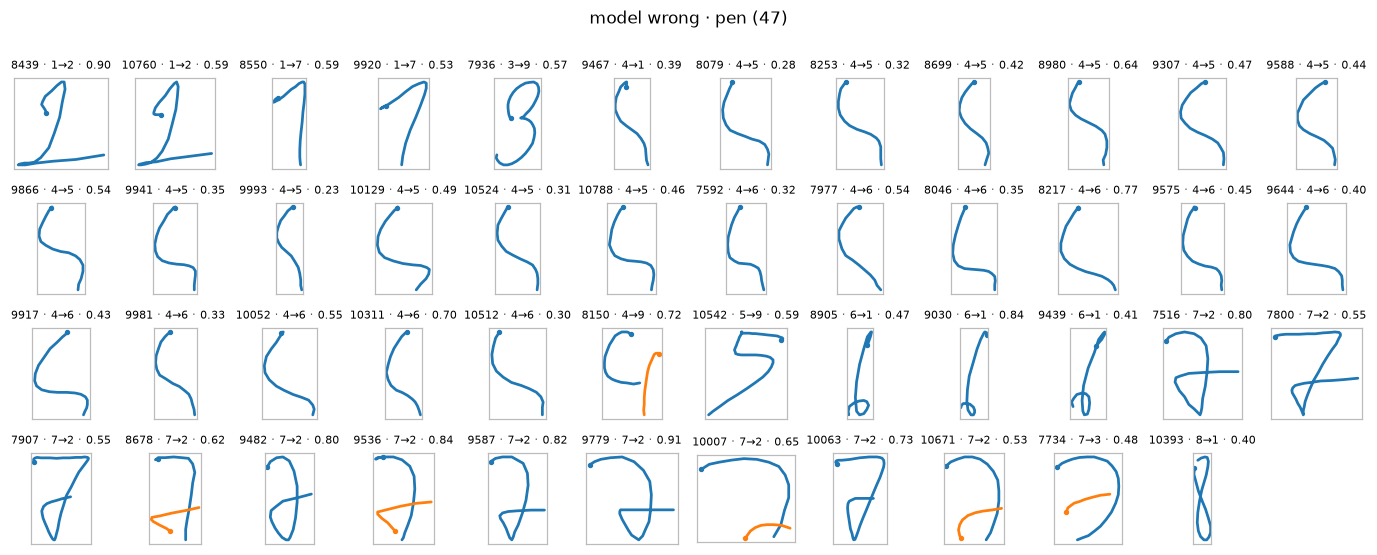

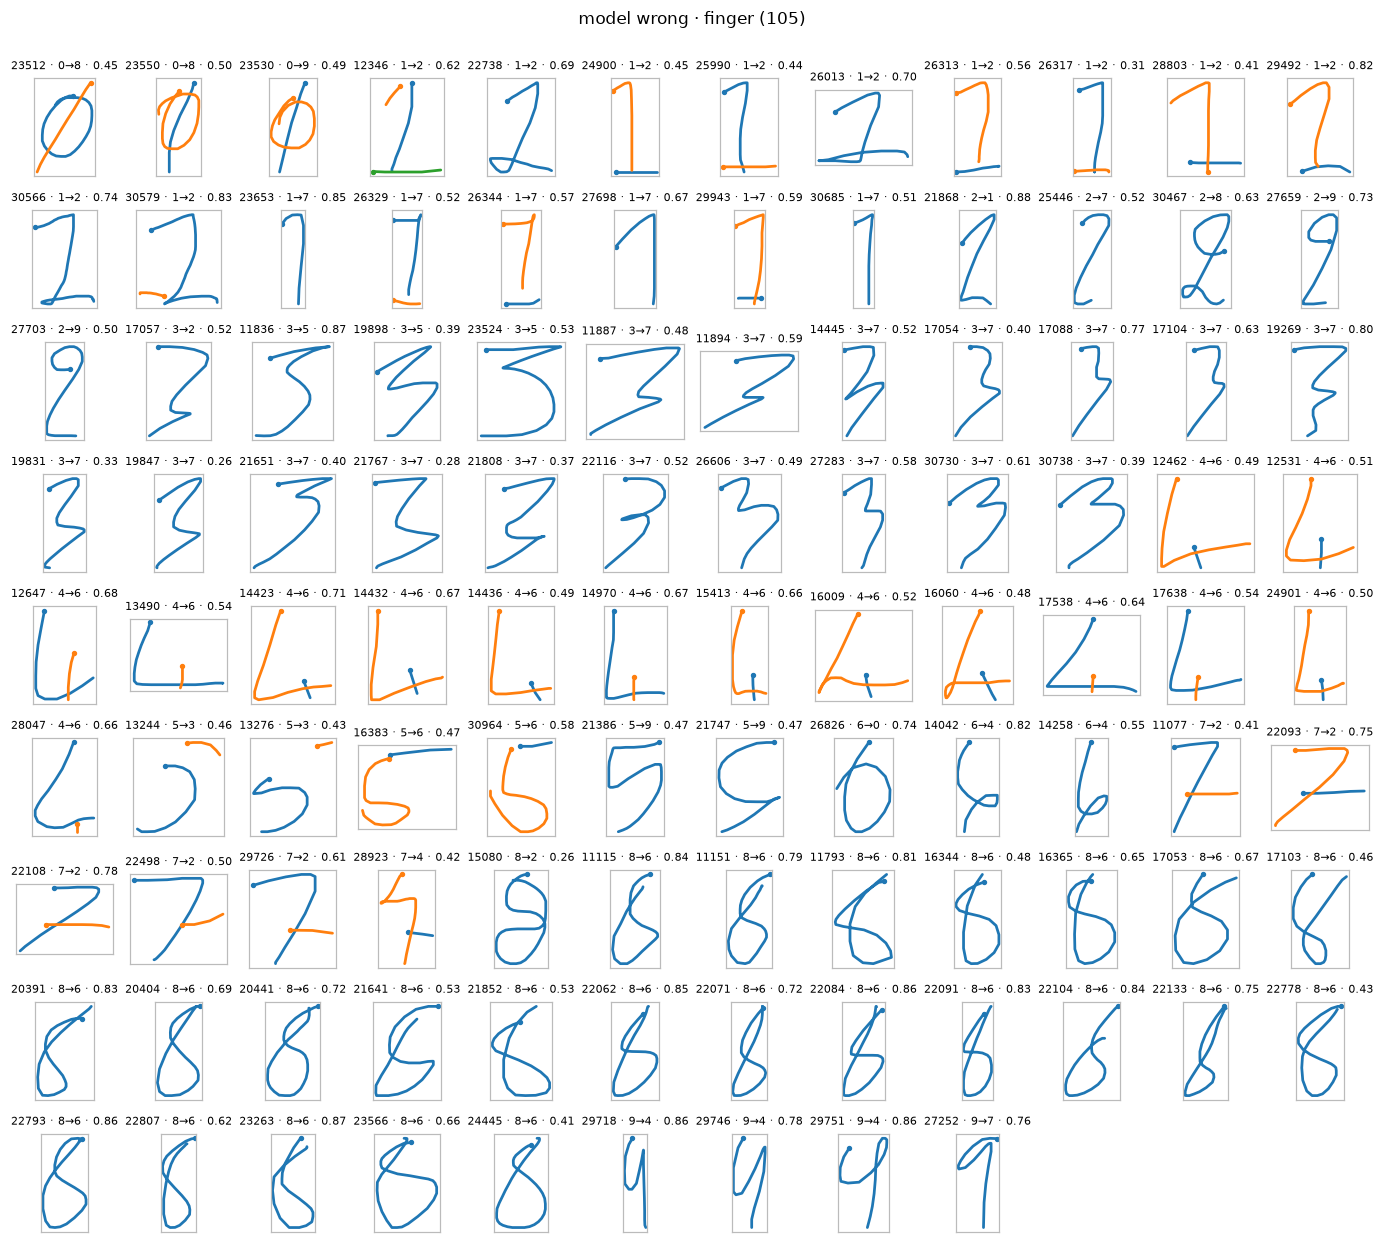

In [7]:
def draw(ax, i, title='', lw=1.8):
    for j, s in enumerate(strokes[i]):
        s = np.asarray(s, float)
        ax.plot(s[:, 0], s[:, 1], '-', lw=lw, color=plt.cm.tab10(j % 10), solid_capstyle='round')
        ax.plot(*s[0], 'o', ms=2.5, color=plt.cm.tab10(j % 10))
    ax.set_aspect('equal'); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_color('#bbb')
    ax.set_title(title, fontsize=7)

def gallery(ids, title, cols=12):
    ids = list(ids)
    if not ids:
        print(title, ': none'); return
    rows_ = (len(ids) + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 1.05, rows_ * 1.25), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on'); draw(ax, i, f'{i} · {y[i]}→{predC[i]} · {pC[i, predC[i]]:.2f}')
    fig.suptitle(title, y=1.0, fontsize=11); plt.tight_layout(); plt.show()

for cat, cname in [('label', 'suspected label error'), ('ambiguous', 'hard even for people'), ('model', 'model wrong')]:
    for s in ['pen', 'finger']:
        sel = audit[(audit.screen == cat) & (audit.set == s)].sort_values(['label', 'pred'])
        gallery(sel.index, f'{cname} · {s} ({len(sel)})')

### 4.1 疑似标签错误：和本人的样本并排看

左边是被怀疑的样本，中间是**同一个人**写的同一个标签数字，右边是同一个人写的模型给出的数字。如果左边明显和右边一组相同，就是写错了数字。

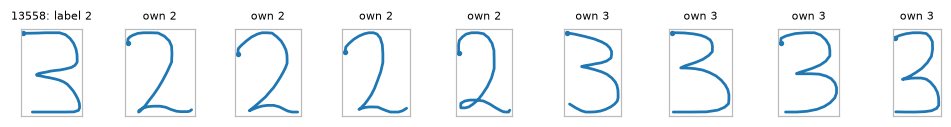

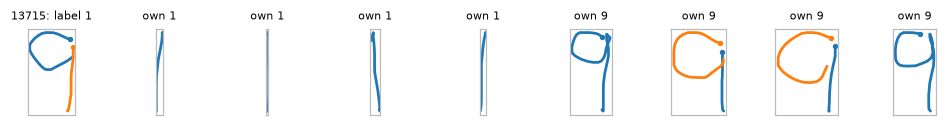

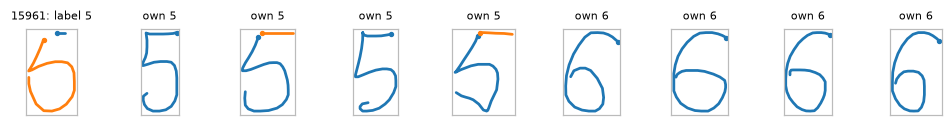

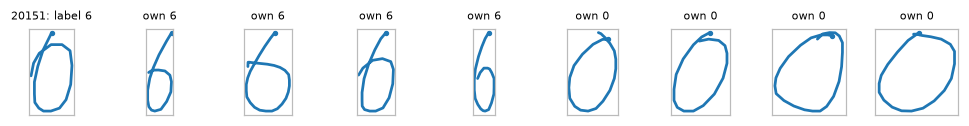

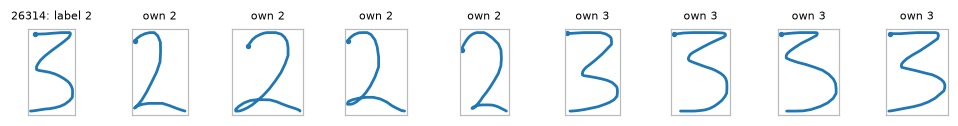

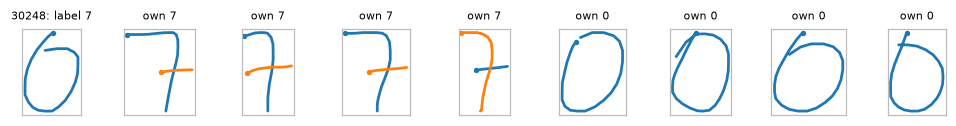

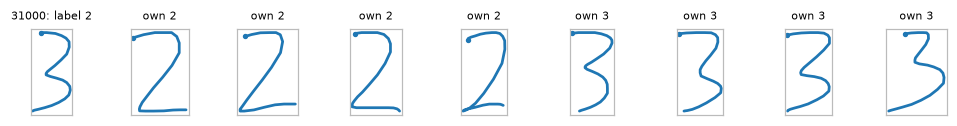

In [8]:
def side_by_side(i, n=4):
    w = by_writer[meta.writer[i]]; w = w[w != i]
    g = [j for j in w if y[j] == y[i]][:n]; p = [j for j in w if y[j] == predC[i]][:n]
    fig, axes = plt.subplots(1, 1 + 2 * n, figsize=(1.0 * (1 + 2 * n), 1.25))
    for ax in axes: ax.axis('off')
    axes[0].axis('on'); draw(axes[0], i, f'{i}: label {y[i]}')
    for ax, j in zip(axes[1:1 + n], g): ax.axis('on'); draw(ax, j, f'own {y[i]}')
    for ax, j in zip(axes[1 + n:], p): ax.axis('on'); draw(ax, j, f'own {predC[i]}')
    plt.tight_layout(); plt.show()

for i in audit.index[audit.screen == 'label']:
    side_by_side(i)

## 5. 触控笔的 4 为什么上不去：一个人的固定写法

第 2.1 节已经能看到：触控笔测试集的错误里，**一个人（`pd-b13`）占了一大半**。下面是这个人写的全部 4，以及他的 7（作为对照：同一个人的 7 模型能认对）。

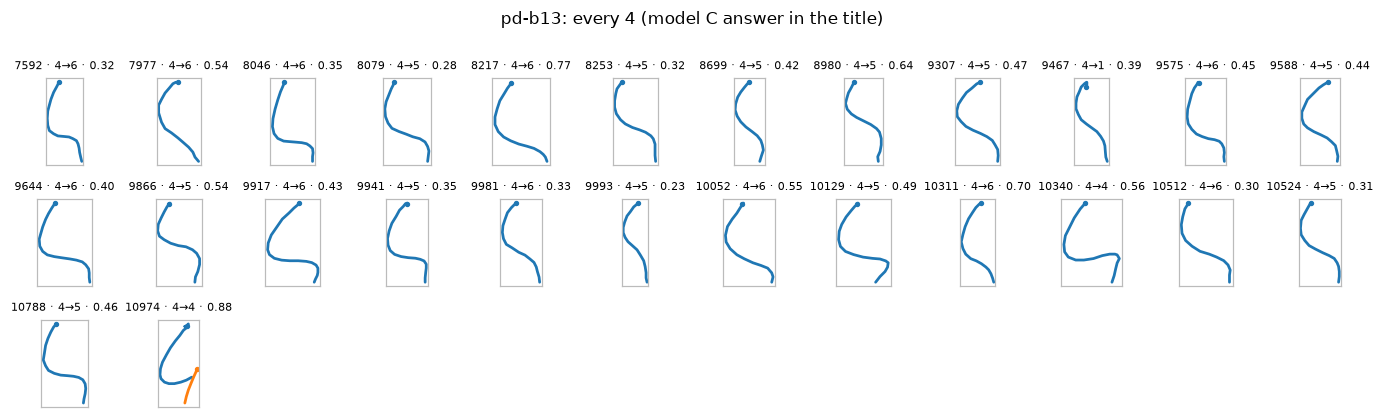

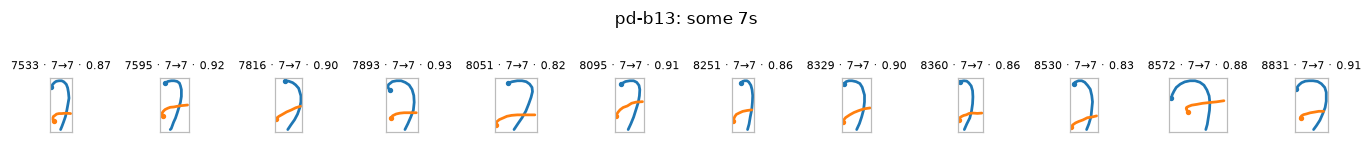

pen 4 accuracy: all writers 92.86% | without pd-b13 99.41%
pen overall:    all writers 98.26% | without pd-b13 99.23%
pd-b13: 85.60% of all their test digits read right; errors by digit: {4: 24, 9: 4, 3: 2, 7: 2, 2: 2, 1: 1, 8: 1}


In [9]:
b13 = conc['pen']['top writer']
w = by_writer[b13]
gallery([i for i in w if y[i] == 4], f'{b13}: every 4 (model C answer in the title)')
gallery([i for i in w if y[i] == 7][:12], f'{b13}: some 7s')

pen = TESTS['pen'].to_numpy()
k4 = pen & (y == 4)
print(f'pen 4 accuracy: all writers {np.mean(predC[k4] == 4):.2%} | without {b13} {np.mean(predC[k4 & (meta.writer != b13).to_numpy()] == 4):.2%}')
print(f'pen overall:    all writers {np.mean(predC[pen] == y[pen]):.2%} | without {b13} {np.mean((predC == y)[pen & (meta.writer != b13).to_numpy()]):.2%}')
print(f'{b13}: {np.mean((predC == y)[w]):.2%} of all their test digits read right; errors by digit:',
      pd.Series(y[w][predC[w] != y[w]]).value_counts().to_dict())

**怎么理解。**这位书写者的 4 是一笔写成的：先向左下斜，再向右横，然后只向下写了竖线的下半截，**竖线没有穿过横线往上**。单独看，人也会读成 5 或者一个弯钩；但他的 20 多个 4 全是这个样子，非常一致。这正是"此人的固定写法"：训练数据里没有，换一个模型结构也学不会（因为它本身就和 5 很像），但只要见过这个人写几次 4 就能认对。所以它属于 notebook 14（个性化）要解决的问题，而不是 notebook 11、12。

## 6. 手指的 8 为什么略降

notebook 09 里，手指的 8 从 97.5%（方案 A）降到 97.0%（方案 C）。看两件事：哪些 8 是"A 认对、C 认错"的；8 的错误集中在谁身上。

{'A right, C wrong': 11, 'A wrong, C right': 4, 'both wrong': 31, 'finger 8s': 1396}
C answers for the 8s it gets wrong: {6: 34, 0: 5, 2: 2, 9: 1}
A answers for the 8s it gets wrong: {6: 24, 0: 7, 9: 3, 7: 1}
errors per writer (C): {'co162': 6, 'co136': 3, 'co171': 3, 'co003': 2, 'co015': 2, 'co056': 2, 'co073': 2, 'co082': 2}


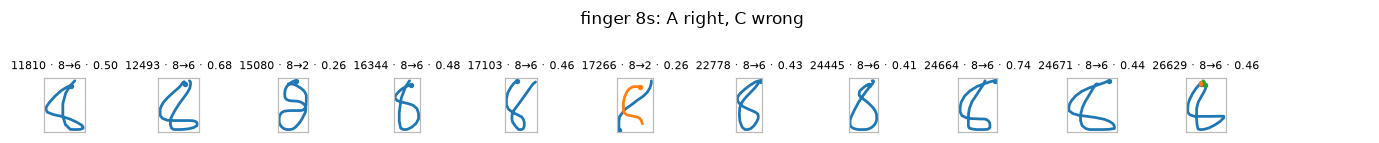

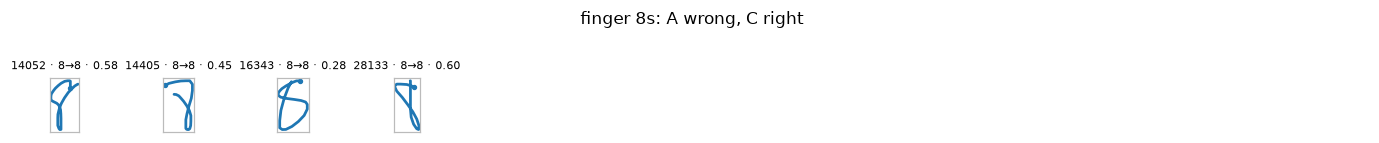

In [10]:
fin = TESTS['finger'].to_numpy()
k8 = fin & (y == 8)
flip = pd.Series({'A right, C wrong': int(np.sum(k8 & (predA == 8) & (predC != 8))),
                  'A wrong, C right': int(np.sum(k8 & (predA != 8) & (predC == 8))),
                  'both wrong': int(np.sum(k8 & (predA != 8) & (predC != 8))), 'finger 8s': int(k8.sum())})
print(flip.to_dict())
print('C answers for the 8s it gets wrong:', pd.Series(predC[k8 & (predC != 8)]).value_counts().to_dict())
print('A answers for the 8s it gets wrong:', pd.Series(predA[k8 & (predA != 8)]).value_counts().to_dict())
print('errors per writer (C):', meta.writer[k8 & (predC != 8)].value_counts().head(8).to_dict())
gallery(np.flatnonzero(k8 & (predA == 8) & (predC != 8)), 'finger 8s: A right, C wrong')
gallery(np.flatnonzero(k8 & (predA != 8) & (predC == 8)), 'finger 8s: A wrong, C right')

### 6.1 这些 8 的共同点：一笔写成、上圈不封口

手指写的 8 很多是一笔：从右上开始，斜着往左下划，在下面绕一个圈，再往上回到起点附近，**上面的圈不封口**。这样的 8 在 28×28 的图里就是"一条斜线加一个下圈"，和 6 几乎一样。下面统计测试集里每个 8 的**上半部分是否封口**（上半部分的笔迹在水平方向有没有左右两边），比较封口与不封口的 8 的准确率。

In [11]:
def top_closed(i):
    """Rough check on the 28x28 input: does some row in the top 40% of the digit box cross ink twice?"""
    rows_ = x[i][4:12] > 0.3                              # the digit sits in the central 20 px
    return max(np.sum(np.diff(np.r_[0, r.astype(int), 0]) == 1) for r in rows_) >= 2

k8i = np.flatnonzero(k8)
closed = np.array([top_closed(i) for i in k8i])
tab = pd.DataFrame({'top loop closed': closed, 'A right': predA[k8i] == 8, 'C right': predC[k8i] == 8})
summ = tab.groupby('top loop closed').agg(n=('A right', 'size'), A_acc=('A right', 'mean'), C_acc=('C right', 'mean'))
summ[['A_acc', 'C_acc']] = (summ[['A_acc', 'C_acc']] * 100).round(1)
summ

,n,A_acc,C_acc
top loop closed,,,
False,29,34.5,24.1
True,1367,98.8,98.5


## 7. 准确率的上限（初筛结果）

- **现在**：方案 C 的测试准确率。
- **修正标签后**：把"疑似标签错误"按模型的答案改标签（等于这些不算错）。
- **上限**：再把"人眼也难分"算作无法避免的错误，剩下的"模型读错"全部修好时能达到的准确率。
- **其中"此人的固定写法"**：只能靠个性化修的部分。

In [12]:
def ceiling(cat_col):
    out = {}
    for name, k in TESTS.items():
        n = int(k.sum()); a = audit[audit.set == name]
        c = a[cat_col].value_counts()
        nl, na, nm = c.get('label', 0), c.get('ambiguous', 0), c.get('model', 0)
        ns = int(((a[cat_col] == 'model') & (a.writer_digit_acc < 0.5)).sum())
        out[name] = {'samples': n, 'errors': len(a), 'label errors': nl, 'hard for people': na, 'model wrong': nm,
                     '  of which writer style': ns,
                     'accuracy now %': 100 * (1 - len(a) / n), 'labels corrected %': 100 * (1 - (na + nm) / n),
                     'ceiling %': 100 * (1 - na / n),
                     'fixable without personalisation %': 100 * (1 - (na + ns) / n)}
    return pd.DataFrame(out).round(2)

ceiling('screen')

,pen,finger
samples,3498.00,14017.00
errors,61.00,168.00
label errors,0.00,7.00
hard for people,14.00,56.00
model wrong,47.00,105.00
of which writer style,24.00,6.00
accuracy now %,98.26,98.80
labels corrected %,98.26,98.85
ceiling %,99.60,99.60
fixable without personalisation %,98.91,99.56


## 8. 请你确认：本地审查网页

下面的代码生成 `cache/audit/review.html`（在 `cache/` 里，不进 git，因为包含数据集的原始笔迹）。用浏览器直接打开这个文件即可，不需要服务器。

- 每张卡片：放大的笔迹（圆点是起点）、模型看到的 28×28 图、方案 C 的前三个答案、初筛类别和理由，以及**同一个人**写的标签数字和模型答案数字各 4 个，方便比较。
- 点按钮改类别；已改过的卡片会标记出来。进度自动存在浏览器里，关掉再开不会丢。
- 可以按数据集、类别筛选；键盘：`1` 模型读错，`2` 人眼也难分，`3` 疑似标签错误，`J` / `K` 下一张 / 上一张。
- 看完点"导出"，会下载 `10_audit_review.json`。把它放到 `mlp_training/research/results/`，再运行第 9 节（或者告诉我下载到了哪里）。

In [13]:
def pack(i):
    pts = [np.asarray(s, float) for s in strokes[i]]
    allp = np.concatenate(pts); lo = allp.min(0); span = max((allp.max(0) - lo).max(), 1e-6)
    return [np.round((s - lo) / span * 100, 1).tolist() for s in pts]

def refs(i, digit, n=4):
    w = by_writer[meta.writer[i]]; w = w[(w != i) & (y[w] == digit)]
    w = w[np.argsort(-(feat[w] @ feat[i]))][:n]            # the writer's samples of that digit most like this one
    return [{'id': int(j), 'ok': bool(predC[j] == y[j]), 's': pack(j)} for j in w]

cards = []
for i, r in audit.sort_values(['set', 'screen', 'label', 'pred']).iterrows():
    top3 = np.argsort(-pC[i])[:3]
    cards.append({'id': int(i), 'set': r.set, 'writer': r.writer, 'label': int(r.label), 'pred': int(r.pred),
                  'top': [[int(t), round(float(pC[i, t]), 3)] for t in top3], 'votes': int(r.votes),
                  'screen': r.screen, 'reason': r.why, 's': pack(i),
                  'img': ''.join(f'{v:02x}' for v in d['x'][i].ravel()),
                  'refLabel': refs(i, r.label), 'refPred': refs(i, r.pred)})

html = (Path('audit_review_template.html').read_text(encoding='utf-8')
        .replace('/*CARDS*/[]', json.dumps(cards, separators=(',', ':'))))
(AUDIT / 'review.html').write_text(html, encoding='utf-8')
print(f'wrote {AUDIT / "review.html"}: {len(cards)} cards, {len(html) / 1e6:.1f} MB')

wrote cache\audit\review.html: 229 cards, 2.4 MB


## 9. 读入你的确认，重新计算

如果 `results/10_audit_review.json` 存在，就用你的类别代替初筛结果，重新算第 7 节的上限，并列出你改动过的样本。还没有确认时，这一节只说明"尚未确认"，后面的保存仍用初筛结果。

In [14]:
REVIEW = RESULTS / '10_audit_review.json'
audit['final'] = audit.screen
if REVIEW.exists():
    rev = json.loads(REVIEW.read_text(encoding='utf-8'))['labels']
    audit['final'] = [rev.get(str(i), s) for i, s in zip(audit.index, audit.screen)]
    changed = audit[audit.final != audit.screen]
    print(f'reviewed: {len(rev)} of {len(audit)} cards; changed from the screen: {len(changed)}')
    print(pd.crosstab(audit.screen, audit.final, margins=True))
    display(ceiling('final'))
    gallery(changed.index, 'cards whose category you changed')
else:
    print('not reviewed yet: the numbers above are the automatic screen')

not reviewed yet: the numbers above are the automatic screen


## 10. 保存

In [15]:
out = {'test_sets': {k: int(v.sum()) for k, v in TESTS.items()},
       'concentration': conc, 'top_pairs': {k: v.to_dict() for k, v in pairs.items()},
       'screen_rules': 'label: own_pred>=3, own_label<=2, votes>=7, p_pred>=0.6; ambiguous: votes<=5 or own_label<=2; else model',
       'visual_pass': [{'category': c, 'reason': w, 'ids': i} for c, w, i in VISUAL],
       'reviewed': REVIEW.exists(),
       'ceiling_rule': ceiling('rule').to_dict(), 'ceiling_screen': ceiling('screen').to_dict(), 'ceiling_final': ceiling('final').to_dict(),
       'finger_8': {'flip': flip.to_dict(), 'top_loop': summ.reset_index().to_dict(orient='records')},
       'errors': audit.reset_index()[['id', 'set', 'writer', 'label', 'pred', 'p_pred', 'votes', 'own_label', 'own_pred',
                                       'writer_digit_acc', 'rule', 'screen', 'final', 'why']].to_dict(orient='records')}
(RESULTS / '10_error_audit.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
print('saved results/10_error_audit.json (sample ids are row numbers in cache/real/real_digits.npz)')

saved results/10_error_audit.json (sample ids are row numbers in cache/real/real_digits.npz)


## 11. 结论与下一步

以下数字来自**初筛结果**（规则 + 我的目视修正）。你确认后重新运行第 9 节，结论里的数字以第 9 节为准。准确率是方案 C 两个种子平均概率后的结果（触控笔 98.26%、手指 98.80%），比 notebook 09 报告的"两个种子各自准确率的平均"（98.17%、98.78%）略高。

**1. 剩下的错误里，大约三分之一修不了。**229 个错误（触控笔 61、手指 168）中，约 70 个是"人眼也难分"：带长勾的 1 和 7、开口的 9、像 6 的单笔 8、缺顶横的 5。把它们算作无法避免，两个测试集的上限都在 **99.6%** 左右。现在离上限还有 1.3 个百分点（触控笔）和 0.8 个百分点（手指）。

**2. 标签错误很少。**手指数据只有 7 个疑似标签错误（被要求写 2 却写成 3 之类），占 0.05%，几乎不影响结论；触控笔一个也没有。规则一开始标出 17 个，看图后 10 个其实是本人一贯的写法（比如带底横的 1、单笔的 8），已改回"模型读错"。所以"用同一个人的其他样本做对照"很有用，但只靠规则会误判。

**3. 触控笔的 4 不是模型的问题，是一个人的问题。**触控笔测试集的 61 个错误里，**36 个来自同一个人**（`pd-b13`），其中 24 个是 4。这个人所有的 4 都是同一种一笔写法，竖线只有横线下面的半截，单独看很像 5。去掉这个人，触控笔的 4 是 **99.4%**，整体是 **99.2%**。这类错误换模型结构也修不好，只能靠个性化（notebook 14）：见过他写几个 4 就能认对。触控笔里能靠"通用模型"修好的空间其实只有 0.65 个百分点（上表 `fixable without personalisation`）。

**4. 手指的 8 下降集中在"上圈不封口"的 8 上。**测试集 1396 个 8 里，只有 29 个上圈不封口（从右上斜着划下来，绕下圈，再回到上面，但上圈没有闭合），它们的准确率是 A 34.5%、C 24.1%；上圈封口的 8 是 98.8%（A）、98.5%（C），几乎没变。也就是说，09 看到的 8 下降几乎都来自这一小类，而且差别只有 3 个样本，在随机波动范围内。这种 8 在 28×28 的图里和 6 几乎一样，但**笔顺**完全不同（6 是从上往下一笔绕圈，结束在圈里；这种 8 结束在顶部）。这正是 notebook 11 的轨迹模型应该能解决的。

**5. 真正值得修的"模型读错"有一批固定的写法**（手指 99 个、触控笔 23 个，都不是个人写法）：
- **平顶的 3**（像带弯的 Z）被读成 7：手指 18 个 3→7 错误的主体；
- **带底横或短勾的 1** 被读成 2 或 7；
- **L 加一小竖的 4** 被读成 6；
- **上下圈清楚交叉的单笔 8** 被读成 6；
- **带横的 7**（欧式写法）被读成 2；
- 触控笔里，**小圈的 6** 被读成 1。

这些在 MNIST 里都很少见。和 09 的结论一致：靠更多这类写法的数据（尤其是你采集的真实样本），以及能利用笔顺的模型，最有希望。

**6. 错误在人群中的分布。**手指测试集 177 人里有 102 人一个错误都没有；错误最多的 5%（9 人）贡献了 33% 的错误。触控笔 14 人里 5 人没有错误。错误明显集中在少数人身上，说明个性化（notebook 14）的收益会比平均准确率显示的大：对那几个人来说，体验差别很大。

**7. 更正 notebook 07。**Corr 数据的笔画先后**可以还原**：`stroke.Z_FOK_GLYPH` 就是真实顺序（第 4 节有验证）。图像结果不受影响，notebook 11 会用它。

**请你确认。**用浏览器打开 `mlp_training/research/cache/audit/review.html`，按 1 / 2 / 3 改类别（J / K 翻页），看完点"导出"，把 `10_audit_review.json` 放到 `mlp_training/research/results/`。不需要每张都看：最值得看的是"人眼也难分"（70 张），因为它直接决定上限。

**下一步：notebook 11（轨迹模型与融合）。**根据上面第 4、5 点，重点看笔顺能不能区分"不封口的 8 和 6"、"平顶的 3 和 7"、"带勾的 1 和 7"。